# ENG5338 CW2 — Virtual CO Sensor (UCI Air Quality)

Group notebook. It reproduces every result in the report.

| Part | Owner | Content |
|---|---|---|
| A | M1 | Data, EDA, question & constraints, shared protocol, Linear/Ridge reference |
| B | M2 | Random Forest |
| C | M3 | HistGradientBoosting |
| D | M4 | SVR / KNN |
| E | M1 | Overfitting analysis |
| F–G | M5 | Computational cost, model selection, final test |

**To run:** put `air-quality.csv` in the same folder as this notebook, then *Restart & Run All*.


## Part A — M1: data, question & constraints, shared protocol, linear reference


### A.1 Import libraries and fix the random seed
Core libraries for data handling and plotting. `RANDOM_STATE = 42` makes every result reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

### A.2 Load the dataset
Load the UCI Air Quality data (hourly readings, March 2004 – April 2005) and sort it by time, because the split later depends on time order.

In [2]:
from pathlib import Path
# Put air-quality.csv in the same folder as this notebook
DATA_PATH = next(p for p in [Path("air-quality.csv"), Path("data/air-quality.csv"), Path("../data/air-quality.csv"), Path("../../data/air-quality.csv"),
                             Path("eng5338-cw2-air-quality/data/air-quality.csv")] if p.exists())
df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)
print(df.shape)
print(df["datetime"].min(), "->", df["datetime"].max())
df.head()

(9357, 14)
2004-03-10 18:00:00 -> 2005-04-04 14:00:00


,datetime,co_gt,pt08_s1_co,nmhc_gt,c6h6_gt,pt08_s2_nmhc,nox_gt,pt08_s3_nox,no2_gt,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity_pct,absolute_humidity
0,2004-03-10 18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,2004-03-10 19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,2004-03-10 20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,2004-03-10 21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,2004-03-10 22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


### A.3 Check missing values
The dataset marks missing readings as `-200`. Replace them with NaN and measure how much of each column is missing.

In [3]:
print("NaN before:", df.isna().sum().sum())
df = df.replace(-200, np.nan)

missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
missing.sort_values("pct", ascending=False)

NaN before: 0


,missing,pct
nmhc_gt,8443,90.2
co_gt,1683,18.0
nox_gt,1639,17.5
no2_gt,1642,17.5
pt08_s1_co,366,3.9
c6h6_gt,366,3.9
pt08_s2_nmhc,366,3.9
pt08_s3_nox,366,3.9
pt08_s4_no2,366,3.9
pt08_s5_o3,366,3.9


### A.4 Clean the data
- Drop `nmhc_gt`: 90% of its values are missing.
- Drop rows with no true CO (`co_gt`): the target is missing there, so those rows cannot be used for training or scoring.

This leaves 7,674 rows. Gaps in the sensor columns are filled later, inside the pipeline.

In [4]:
df = df.drop(columns=["nmhc_gt"])
df = df.dropna(subset=["co_gt"]).reset_index(drop=True)
print(len(df), "rows remain")

7674 rows remain


### A.5 Summary statistics
Define the target (`co_gt`, true CO in mg/m³) and the input groups (5 low-cost sensors and 3 weather variables), then look at their ranges.

In [5]:
SENSOR_COLS  = ["pt08_s1_co", "pt08_s2_nmhc", "pt08_s3_nox", "pt08_s4_no2", "pt08_s5_o3"]
WEATHER_COLS = ["temperature_c", "relative_humidity_pct", "absolute_humidity"]
TARGET = "co_gt"

df[[TARGET] + SENSOR_COLS + WEATHER_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
co_gt,7674.0,2.15,1.45,0.10,1.10,1.80,2.90,11.90
pt08_s1_co,7344.0,1110.58,218.68,647.00,946.00,1075.00,1246.00,2040.00
pt08_s2_nmhc,7344.0,947.20,265.47,387.00,743.00,919.00,1125.25,2214.00
pt08_s3_nox,7344.0,826.92,256.65,322.00,649.00,795.00,960.00,2683.00
pt08_s4_no2,7344.0,1444.75,350.34,551.00,1203.00,1447.00,1673.00,2775.00
pt08_s5_o3,7344.0,1043.51,405.57,221.00,744.75,990.00,1305.00,2523.00
temperature_c,7344.0,17.77,8.86,-1.90,11.20,16.90,23.80,44.60
relative_humidity_pct,7344.0,49.06,17.45,9.20,35.40,49.30,62.50,88.70
absolute_humidity,7344.0,0.99,0.40,0.18,0.70,0.96,1.26,2.18


### A.6 EDA: target distribution and daily pattern
CO is right-skewed and peaks at the morning and evening rush hours. This is why time of day is used as a feature.

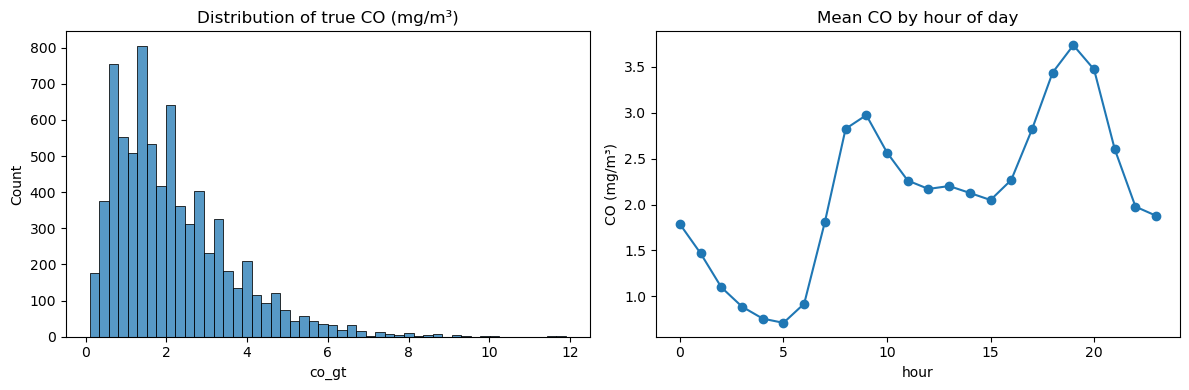

In [6]:
df["hour"] = df["datetime"].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0])
ax[0].set_title("Distribution of true CO (mg/m³)")

df.groupby("hour")[TARGET].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("Mean CO by hour of day")
ax[1].set_ylabel("CO (mg/m³)")
plt.tight_layout(); plt.show()

### A.7 EDA: correlation matrix
The sensors are strongly correlated with true CO (about 0.63–0.92 in absolute value). The weather variables are not correlated with it directly, but they can affect sensor behaviour.

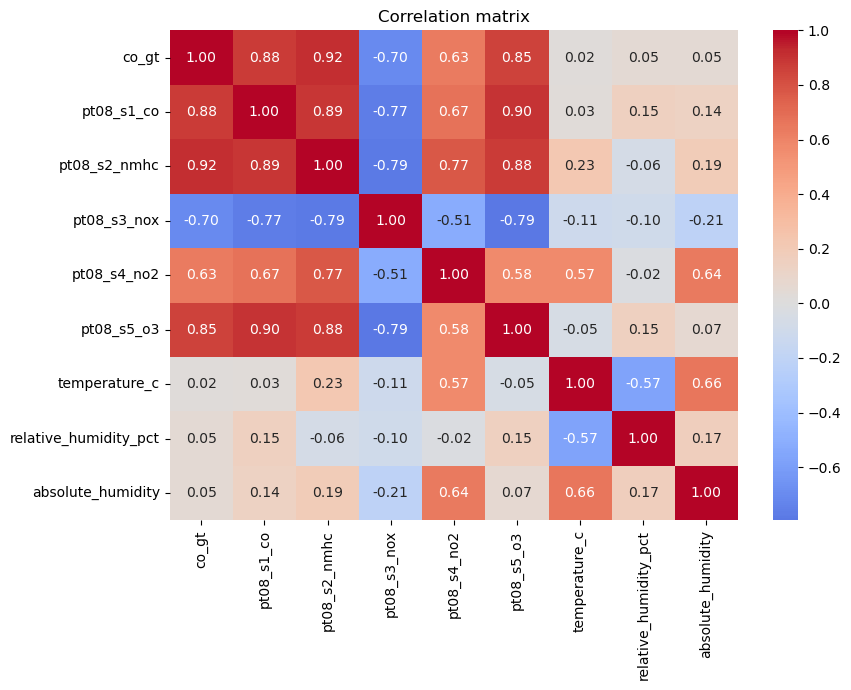

pt08_s2_nmhc             0.915514
pt08_s1_co               0.879288
pt08_s5_o3               0.854182
pt08_s4_no2              0.630703
relative_humidity_pct    0.048890
absolute_humidity        0.048556
temperature_c            0.022109
pt08_s3_nox             -0.703446
Name: co_gt, dtype: float64

In [7]:
corr = df[[TARGET] + SENSOR_COLS + WEATHER_COLS].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

corr[TARGET].drop(TARGET).sort_values(ascending=False)

### A.8 EDA: true CO vs the CO sensor over time
Daily means show that the link between the sensor and true CO changes over the year (sensor drift). This motivates a time-based split instead of a random one.

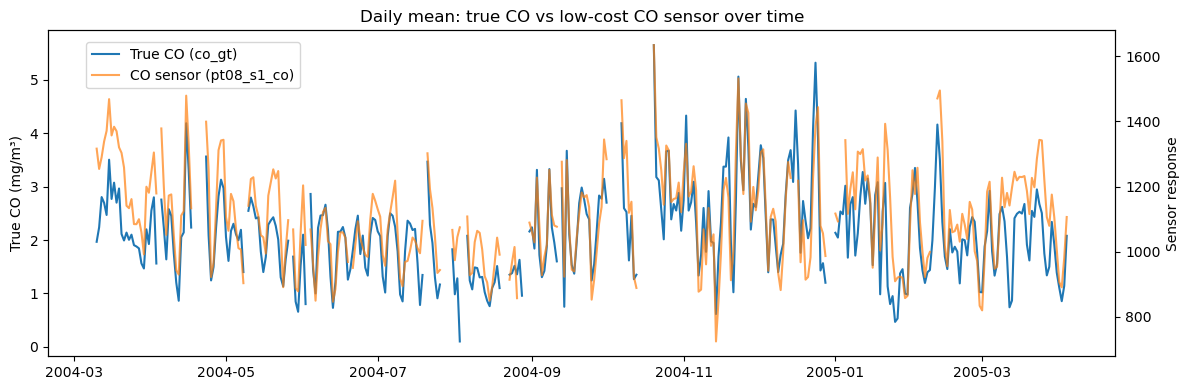

In [8]:
daily = df.set_index("datetime")[[TARGET, "pt08_s1_co"]].resample("D").mean()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(daily.index, daily[TARGET], label="True CO (co_gt)", color="tab:blue")
ax1.set_ylabel("True CO (mg/m³)")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["pt08_s1_co"], label="CO sensor (pt08_s1_co)", color="tab:orange", alpha=0.7)
ax2.set_ylabel("Sensor response")
ax1.set_title("Daily mean: true CO vs low-cost CO sensor over time")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.tight_layout(); plt.show()

### A.9 Feature engineering: calendar features
Add hour of day, weekday and a weekend flag, to capture traffic patterns.

In [9]:
df["hour"] = df["datetime"].dt.hour            # 0 to 23
df["weekday"] = df["datetime"].dt.weekday      # 0 = Monday ... 6 = Sunday
df["is_weekend"] = (df["weekday"] >= 5).astype(int)   # 1 if Sat/Sun, else 0

### A.10 Feature engineering: cyclic encoding of hour
Encode the hour as sine/cosine so that 23:00 and 00:00 end up close together.

In [10]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

### A.11 Final feature set
12 features: 5 sensors, 3 weather variables and 4 time features. All models use this same list.

In [11]:
SENSOR_COLS  = ["pt08_s1_co", "pt08_s2_nmhc", "pt08_s3_nox", "pt08_s4_no2", "pt08_s5_o3"]
WEATHER_COLS = ["temperature_c", "relative_humidity_pct", "absolute_humidity"]
TIME_COLS    = ["hour_sin", "hour_cos", "weekday", "is_weekend"]

FEATURES = SENSOR_COLS + WEATHER_COLS + TIME_COLS
TARGET = "co_gt"

print(len(FEATURES), "features:", FEATURES)

12 features: ['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3', 'temperature_c', 'relative_humidity_pct', 'absolute_humidity', 'hour_sin', 'hour_cos', 'weekday', 'is_weekend']


### A.12 Chronological train/test split (80/20)
The first 80% of the timeline is used for training, the last 20% (Jan–Apr 2005) for testing. The test set stays untouched until the final recommended model is scored once.

In [12]:
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df  = df.iloc[split_idx:]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print(f"Train: {len(train_df)} rows  {train_df.datetime.min():%Y-%m-%d} -> {train_df.datetime.max():%Y-%m-%d}")
print(f"Test : {len(test_df)} rows  {test_df.datetime.min():%Y-%m-%d} -> {test_df.datetime.max():%Y-%m-%d}")

Train: 6139 rows  2004-03-10 -> 2005-01-29
Test : 1535 rows  2005-01-29 -> 2005-04-04


### A.13 Cross-validation: TimeSeriesSplit (5 folds)
Each fold trains on the past and validates on the next block of time, so no future data leaks into training.

In [13]:
from sklearn.model_selection import TimeSeriesSplit

CV = TimeSeriesSplit(n_splits=5)
for i, (tr, va) in enumerate(CV.split(X_train)):
    print(f"Fold {i+1}: train {len(tr):5d} rows | validate {len(va):4d} rows "
          f"({train_df.datetime.iloc[va[0]]:%Y-%m-%d} -> {train_df.datetime.iloc[va[-1]]:%Y-%m-%d})")

Fold 1: train  1024 rows | validate 1023 rows (2004-05-02 -> 2004-06-23)
Fold 2: train  2047 rows | validate 1023 rows (2004-06-23 -> 2004-08-16)
Fold 3: train  3070 rows | validate 1023 rows (2004-08-16 -> 2004-10-27)
Fold 4: train  4093 rows | validate 1023 rows (2004-10-27 -> 2004-12-10)
Fold 5: train  5116 rows | validate 1023 rows (2004-12-10 -> 2005-01-29)


### A.14 Constraints and scoring metrics
- **C1 (accuracy):** at least 90% of predictions within ±0.5 mg/m³ of the true CO.
- **C2 (latency):** prediction time of at most 1 ms per sample.

Metrics are MAE (primary, used to choose the best settings), RMSE, R² and % within tolerance.

In [14]:
from sklearn.metrics import make_scorer

TOLERANCE = 0.5          # mg/m³ – constraint 1
TARGET_PCT = 90          # %     – constraint 1
LATENCY_LIMIT_MS = 1.0   # ms per sample – constraint 2

def pct_within(y_true, y_pred, tol=TOLERANCE):
    return 100 * np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= tol)

SCORING = {
    "mae":    "neg_mean_absolute_error",
    "rmse":   "neg_root_mean_squared_error",
    "r2":     "r2",
    "within": make_scorer(pct_within),
}
PRIMARY = "mae"

### A.15 Shared preprocessing
Median imputation, plus scaling where the model needs it. It sits inside the pipeline, so it is fitted on each training fold only and nothing leaks into validation.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def make_preprocessor(scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(steps), FEATURES)])

### A.16 Shared evaluation harness
`run_search()` tunes a model with GridSearchCV under the shared protocol. It records training scores beside validation scores, the overfitting gap and the fit time, and notes the hardware the times were measured on. Every model in the group uses this function.

In [16]:
from sklearn.model_selection import GridSearchCV
import platform, os

RUNTIME = f"{platform.processor() or platform.machine()} | {os.cpu_count()} CPU cores | Python {platform.python_version()}"
print("Runtime:", RUNTIME)

results = []   # every model adds one row here

def evaluate_search(name, gs):
    r, i = gs.cv_results_, gs.best_index_
    row = {
        "model": name,
        "train_MAE": -r["mean_train_mae"][i],
        "val_MAE":   -r["mean_test_mae"][i],
        "val_MAE_std": r["std_test_mae"][i],
        "train_R2": r["mean_train_r2"][i],
        "val_R2":   r["mean_test_r2"][i],
        "train_within_%": r["mean_train_within"][i],
        "val_within_%":   r["mean_test_within"][i],
        "mean_fit_time_s": r["mean_fit_time"][i],
        "best_params": gs.best_params_,
    }
    row["overfit_gap_MAE"] = row["val_MAE"] - row["train_MAE"]
    results.append(row)
    return pd.Series(row)

def run_search(name, pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit=PRIMARY,
                      return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs, evaluate_search(name, gs)

Runtime: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel | 12 CPU cores | Python 3.12.7


### A.17 Reference model: Linear Regression
The linear reference that the brief requires. It has no hyperparameters to tune.

In [17]:
from sklearn.linear_model import LinearRegression
lin_pipe = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
lin_gs, lin_res = run_search("Linear Regression", lin_pipe, {})
lin_res


model              Linear Regression
train_MAE                   0.254667
val_MAE                     0.450405
val_MAE_std                 0.120358
train_R2                    0.927522
val_R2                      0.788732
train_within_%             88.006838
val_within_%                 68.5826
mean_fit_time_s             0.023854
best_params                       {}
overfit_gap_MAE             0.195738
dtype: object

### A.18 Reference model: Ridge Regression (tuned alpha)
Linear regression with L2 regularisation. Alpha is tuned over 10⁻³ to 10³. It reduces the overfitting gap compared with plain Linear Regression.

In [18]:
from sklearn.linear_model import Ridge
ridge_pipe = Pipeline([("prep", make_preprocessor()), ("model", Ridge())])
ridge_grid = {"model__alpha": np.logspace(-3, 3, 13)}
ridge_gs, ridge_res = run_search("Ridge (baseline)", ridge_pipe, ridge_grid)
ridge_res

model                                  Ridge (baseline)
train_MAE                                      0.282868
val_MAE                                        0.430359
val_MAE_std                                    0.150591
train_R2                                       0.912831
val_R2                                         0.806051
train_within_%                                84.966868
val_within_%                                   72.57087
mean_fit_time_s                                0.009756
best_params        {'model__alpha': 316.22776601683796}
overfit_gap_MAE                                0.147491
dtype: object

## Part B — M2: Random Forest


In [19]:

# ==========================================
# RANDOM FOREST — REGULARISED EXPERIMENT
# ==========================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_pipe = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

# Hyperparameter grid: 8 configurations
rf_grid_regularised = {
    "model__n_estimators": [300],
    "model__max_depth": [10, 20],
    "model__min_samples_leaf": [5, 10],
    "model__max_features": [0.7, "sqrt"]
}

print("Random Forest pipeline created.")
print("Configurations:", 8)
print("Cross-validation folds:", CV.get_n_splits())

# Train and evaluate
rf_gs_reg, rf_res_reg = run_search(
    "Random Forest (Regularised)",
    rf_pipe,
    rf_grid_regularised
)

print("\nRegularised Random Forest results:")
display(rf_res_reg)


Random Forest pipeline created.
Configurations: 8
Cross-validation folds: 5



Regularised Random Forest results:


model                                    Random Forest (Regularised)
train_MAE                                                   0.141669
val_MAE                                                     0.371015
val_MAE_std                                                 0.155075
train_R2                                                    0.973324
val_R2                                                      0.829568
train_within_%                                              96.42998
val_within_%                                               78.963832
mean_fit_time_s                                             3.160869
best_params        {'model__max_depth': 10, 'model__max_features'...
overfit_gap_MAE                                             0.229346
dtype: object

In [20]:
print("Best regularised Random Forest parameters:")
print(rf_gs_reg.best_params_)

Best regularised Random Forest parameters:
{'model__max_depth': 10, 'model__max_features': 0.7, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}


> **Note:** this cell scores the test set during the owner's own exploration. It is **not** used for model selection. The group's single official test score is in **Part H.6**.

In [21]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import time
import numpy as np

# Final selected Random Forest
rf_final = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train using training data only
rf_final.fit(X_train, y_train)

# Predict on untouched test data ONCE
start = time.perf_counter()
y_test_pred = rf_final.predict(X_test)
prediction_time = time.perf_counter() - start

# Calculate final test metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)
test_within = pct_within(y_test, y_test_pred)

latency_ms = prediction_time * 1000 / len(X_test)

print("FINAL RANDOM FOREST TEST RESULTS")
print("--------------------------------")
print("Test MAE:", round(test_mae, 4))
print("Test RMSE:", round(test_rmse, 4))
print("Test R2:", round(test_r2, 4))
print("Within tolerance (%):", round(test_within, 2))
print("Prediction latency (ms/sample):", round(latency_ms, 4))
print("Meets 90% tolerance target:", test_within >= TARGET_PCT)
print("Meets 1 ms latency limit:", latency_ms <= LATENCY_LIMIT_MS)


FINAL RANDOM FOREST TEST RESULTS
--------------------------------
Test MAE: 0.3685
Test RMSE: 0.6002
Test R2: 0.8007
Within tolerance (%): 77.52
Prediction latency (ms/sample): 0.0521
Meets 90% tolerance target: False
Meets 1 ms latency limit: True


In [22]:
import pandas as pd

feature_importance = pd.Series(
    rf_final.named_steps["model"].feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

print("Random Forest Feature Importance:")
display(feature_importance.to_frame("Importance"))

Random Forest Feature Importance:


,Importance
pt08_s2_nmhc,0.860423
temperature_c,0.029866
pt08_s1_co,0.021639
hour_sin,0.016311
pt08_s3_nox,0.015375
weekday,0.013617
hour_cos,0.010840
pt08_s5_o3,0.010769
absolute_humidity,0.007102
relative_humidity_pct,0.006117


In [23]:
# Diagnose Random Forest prediction errors

errors = np.abs(np.asarray(y_test) - np.asarray(y_test_pred))

print("Total test predictions:", len(errors))
print("Predictions within tolerance:", np.sum(errors <= TOLERANCE))
print("Predictions outside tolerance:", np.sum(errors > TOLERANCE))
print("Average absolute error:", round(np.mean(errors), 4))
print("Median absolute error:", round(np.median(errors), 4))
print("90th percentile error:", round(np.percentile(errors, 90), 4))
print("Maximum error:", round(np.max(errors), 4))

Total test predictions: 1535
Predictions within tolerance: 1190
Predictions outside tolerance: 345
Average absolute error: 0.3685
Median absolute error: 0.2042
90th percentile error: 0.9568
Maximum error: 4.4124


In [24]:
# Compare actual CO values with prediction errors

diagnostic_df = pd.DataFrame({
    "Actual_CO": np.asarray(y_test),
    "Predicted_CO": np.asarray(y_test_pred),
    "Absolute_Error": errors
})

diagnostic_df["Within_Tolerance"] = (
    diagnostic_df["Absolute_Error"] <= TOLERANCE
)

diagnostic_df.groupby(
    pd.cut(diagnostic_df["Actual_CO"], bins=5)
).agg(
    Count=("Absolute_Error", "count"),
    Mean_Error=("Absolute_Error", "mean"),
    Within_Tolerance=("Within_Tolerance", "mean")
)

C:\Users\91947\AppData\Local\Temp\ipykernel_14316\130153051.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diagnostic_df.groupby(


,Count,Mean_Error,Within_Tolerance
Actual_CO,,,
"(0.0917, 1.76]",822,0.250692,0.871046
"(1.76, 3.42]",500,0.381314,0.774000
"(3.42, 5.08]",151,0.687850,0.390728
"(5.08, 6.74]",54,0.949836,0.481481
"(6.74, 8.4]",8,1.725505,0.250000


In [25]:
print("Training target distribution:")
print(y_train.describe())

print("\nTraining CO values above 3.42:")
print((y_train > 3.42).sum())

print("Training CO values above 5.08:")
print((y_train > 5.08).sum())

Training target distribution:
count    6139.000000
mean        2.190406
std         1.476797
min         0.100000
25%         1.100000
50%         1.900000
75%         2.900000
max        11.900000
Name: co_gt, dtype: float64

Training CO values above 3.42:
1059
Training CO values above 5.08:
282


In [26]:
rf_grid_improved = {
    "model__n_estimators": [400, 600],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [1.0]
}

rf_gs_improved, rf_res_improved = run_search(
    "Random Forest (Improved)",
    rf_pipe,
    rf_grid_improved
)

In [27]:
print(rf_res_improved)

model                                       Random Forest (Improved)
train_MAE                                                   0.086785
val_MAE                                                     0.369027
val_MAE_std                                                 0.164141
train_R2                                                    0.988884
val_R2                                                      0.827241
train_within_%                                             98.868793
val_within_%                                               79.217986
mean_fit_time_s                                            11.539415
best_params        {'model__max_depth': None, 'model__max_feature...
overfit_gap_MAE                                             0.282243
dtype: object


In [28]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer

rf_log_pipe = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_leaf=3,
            max_features=1.0,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

rf_log_grid = {
    "model__regressor__min_samples_leaf": [3, 5, 10],
    "model__regressor__max_depth": [None, 20]
}

rf_log_gs, rf_log_res = run_search(
    "Random Forest (Log Target)",
    rf_log_pipe,
    rf_log_grid
)

In [29]:
print(rf_log_res)

model                                     Random Forest (Log Target)
train_MAE                                                   0.129326
val_MAE                                                     0.370954
val_MAE_std                                                 0.164404
train_R2                                                    0.976417
val_R2                                                      0.828864
train_within_%                                             96.915017
val_within_%                                               78.963832
mean_fit_time_s                                             6.023579
best_params        {'model__regressor__max_depth': None, 'model__...
overfit_gap_MAE                                             0.241628
dtype: object


In [30]:
# Give higher CO concentrations more training weight

sample_weights = np.where(
    np.asarray(y_train) > 3.42,
    2.0,
    1.0
)

print("Normal-weight samples:", np.sum(sample_weights == 1.0))
print("Higher-weight samples:", np.sum(sample_weights == 2.0))

Normal-weight samples: 5080
Higher-weight samples: 1059


In [31]:
rf_weighted = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_weighted.fit(
    X_train,
    y_train,
    model__sample_weight=sample_weights
)

print("Weighted Random Forest training completed!")

Weighted Random Forest training completed!


In [32]:
from sklearn.model_selection import TimeSeriesSplit

cv = TimeSeriesSplit(n_splits=5)

print("Cross-validation restored:", cv)

Cross-validation restored: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)


In [33]:
from sklearn.model_selection import cross_validate

weighted_cv = cross_validate(
    rf_weighted,
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=True
)

print("Weighted RF validation MAE:",
      round(-weighted_cv["test_mae"].mean(), 4))

print("Weighted RF validation within tolerance:",
      round(weighted_cv["test_within"].mean(), 2), "%")

Weighted RF validation MAE: 0.368
Weighted RF validation within tolerance: 79.32 %


In [34]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

weight_results = []

for weight in [1.5, 3.0, 5.0]:

    weights = np.where(
        np.asarray(y_train) > 3.42,
        weight,
        1.0
    )

    model = clone(rf_pipe)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=-1,
        params={"model__sample_weight": weights}
    )

    weight_results.append({
        "Weight": weight,
        "Validation_MAE": -scores["test_mae"].mean(),
        "Within_Tolerance_%": scores["test_within"].mean()
    })

weight_results_df = pd.DataFrame(weight_results)
display(weight_results_df.round(4))

,Weight,Validation_MAE,Within_Tolerance_%
0,1.5,0.3706,79.1593
1,3.0,0.3692,79.4721
2,5.0,0.3711,79.3353


In [35]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

range_weight_results = []

for high_weight in [3.0, 5.0, 8.0]:

    weights = np.ones(len(y_train))

    weights[np.asarray(y_train) > 3.42] = 3.0
    weights[np.asarray(y_train) > 5.08] = high_weight

    model = clone(rf_pipe)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=-1,
        params={"model__sample_weight": weights}
    )

    range_weight_results.append({
        "High_CO_Weight": high_weight,
        "Validation_MAE": -scores["test_mae"].mean(),
        "Within_Tolerance_%": scores["test_within"].mean()
    })

display(pd.DataFrame(range_weight_results).round(4))

,High_CO_Weight,Validation_MAE,Within_Tolerance_%
0,3.0,0.3692,79.4721
1,5.0,0.3714,79.3939
2,8.0,0.3716,79.2962


## Part C — M3: HistGradientBoosting


In [36]:
# C.1 Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

In [37]:
# C.2 Check shared training data and evaluation setup

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nAvailable features:")
print(X_train.columns.tolist())

print("\nSearch function available:", callable(run_search))
print("Cross-validation setup:", CV)
print("Scoring metrics:", SCORING.keys())

Training features: (6139, 12)
Training target: (6139,)

Available features:
['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3', 'temperature_c', 'relative_humidity_pct', 'absolute_humidity', 'hour_sin', 'hour_cos', 'weekday', 'is_weekend']

Search function available: True
Cross-validation setup: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)
Scoring metrics: dict_keys(['mae', 'rmse', 'r2', 'within'])


In [38]:
# C.3 HistGradientBoosting model pipeline

hgb_pipe = Pipeline([
    ("model", HistGradientBoostingRegressor(
        random_state=42
    ))
])

print("HistGradientBoosting pipeline created successfully.")

HistGradientBoosting pipeline created successfully.


In [39]:
# C.4 Define hyperparameter search space

hgb_grid = {
    "model__learning_rate": [0.05],
    "model__max_iter": [100, 200],
    "model__max_leaf_nodes": [7, 15, 31],
    "model__l2_regularization": [0, 0.5]
}

print("Number of parameter combinations:",
      np.prod([len(v) for v in hgb_grid.values()]))

Number of parameter combinations: 12


In [40]:
# C.5 Hyperparameter optimisation

hgb_search, hgb_results = run_search(
    "HistGradientBoosting",
    hgb_pipe,
    hgb_grid
)

print("Best hyperparameters:")
print(hgb_search.best_params_)

print("\nBest validation MAE:")
print(-hgb_search.best_score_)

Best hyperparameters:
{'model__l2_regularization': 0.5, 'model__learning_rate': 0.05, 'model__max_iter': 100, 'model__max_leaf_nodes': 15}

Best validation MAE:
0.3597351303713638


In [41]:
# C.6 Best model evaluation

best_hgb_results = pd.DataFrame([hgb_results])

display(best_hgb_results.T)

,0
model,HistGradientBoosting
train_MAE,0.163997
val_MAE,0.359735
val_MAE_std,0.175607
train_R2,0.966927
val_R2,0.829636
train_within_%,95.393338
val_within_%,80.821114
mean_fit_time_s,0.19271
best_params,"{'model__l2_regularization': 0.5, 'model__lear..."


In [42]:
# C.7 Generate out-of-fold predictions using TimeSeriesSplit

from sklearn.base import clone

cv_actual = []
cv_predictions = []
cv_indices = []

for fold, (train_idx, val_idx) in enumerate(
    CV.split(X_train, y_train), start=1
):
    fold_model = clone(hgb_search.best_estimator_)

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = fold_model.predict(X_train.iloc[val_idx])

    cv_actual.extend(y_train.iloc[val_idx].to_numpy())
    cv_predictions.extend(predictions)
    cv_indices.extend(val_idx)

print("Number of CV predictions:", len(cv_predictions))
print("Number of actual values:", len(cv_actual))
print("Number of folds:", fold)

Number of CV predictions: 5115
Number of actual values: 5115
Number of folds: 5


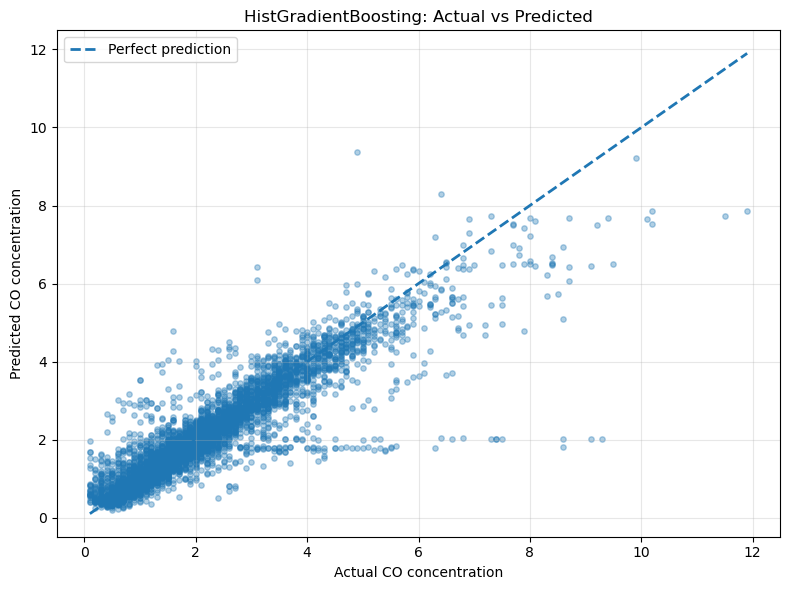

In [43]:
# C.8 Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(
    cv_actual,
    cv_predictions,
    alpha=0.35,
    s=15
)

# Ideal prediction line
min_val = min(min(cv_actual), min(cv_predictions))
max_val = max(max(cv_actual), max(cv_predictions))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual CO concentration")
plt.ylabel("Predicted CO concentration")
plt.title("HistGradientBoosting: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("hgb_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


In [44]:
print("ACTUAL VS PREDICTED ANALYSIS")
print("-" * 45)
print("Most predictions follow the ideal prediction line.")
print("Prediction errors become larger at higher CO concentrations.")
print("The model tends to underestimate some high CO values.")

ACTUAL VS PREDICTED ANALYSIS
---------------------------------------------
Most predictions follow the ideal prediction line.
Prediction errors become larger at higher CO concentrations.
The model tends to underestimate some high CO values.


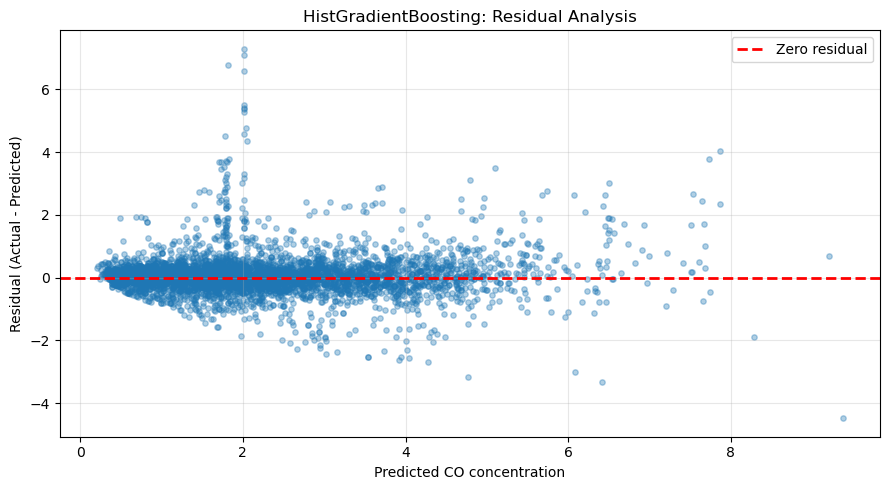

In [45]:
# C.9 Residual Analysis

residuals = np.array(cv_actual) - np.array(cv_predictions)

plt.figure(figsize=(9, 5))

plt.scatter(
    cv_predictions,
    residuals,
    alpha=0.35,
    s=15
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero residual"
)

plt.xlabel("Predicted CO concentration")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("HistGradientBoosting: Residual Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("hgb_residual_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


In [46]:
print("RESIDUAL ANALYSIS")
print("-" * 45)
print("Residuals are generally centred around zero.")
print("The spread increases at higher predicted concentrations.")
print("Some significant positive and negative residuals are present.")

RESIDUAL ANALYSIS
---------------------------------------------
Residuals are generally centred around zero.
The spread increases at higher predicted concentrations.
Some significant positive and negative residuals are present.


In [47]:
# C.10 Prepare validation fold for permutation importance

from sklearn.base import clone

train_idx, val_idx = list(CV.split(X_train, y_train))[-1]

importance_model = clone(hgb_search.best_estimator_)

importance_model.fit(
    X_train.iloc[train_idx],
    y_train.iloc[train_idx]
)

X_importance = X_train.iloc[val_idx]
y_importance = y_train.iloc[val_idx]

print("Validation fold shape:", X_importance.shape)

Validation fold shape: (1023, 12)


In [48]:
# C.11 Permutation Feature Importance

importance = permutation_importance(
    importance_model,
    X_importance,
    y_importance,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance,Std
1,pt08_s2_nmhc,0.678319,0.026139
8,hour_sin,0.029054,0.005165
10,weekday,0.011179,0.001591
9,hour_cos,0.003821,0.001640
0,pt08_s1_co,0.001452,0.005663
6,relative_humidity_pct,0.000186,0.002160
11,is_weekend,0.000000,0.000000
4,pt08_s5_o3,-0.001115,0.001184
3,pt08_s4_no2,-0.001331,0.000501
2,pt08_s3_nox,-0.002288,0.001402


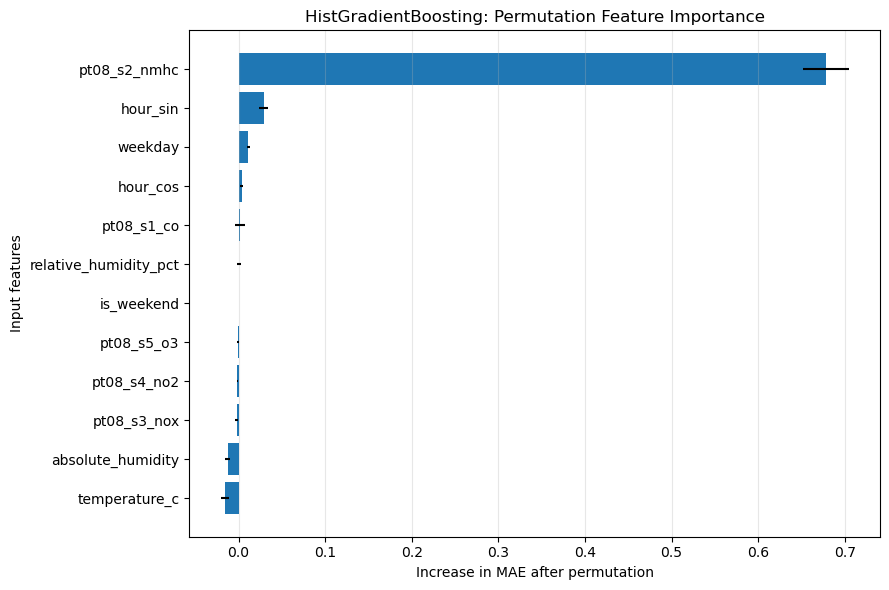

In [49]:
# C.12 Feature Importance Visualisation

plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.xlabel("Increase in MAE after permutation")
plt.ylabel("Input features")
plt.title("HistGradientBoosting: Permutation Feature Importance")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("hgb_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


In [50]:
# C.12 Feature Importance Interpretation

print("FEATURE IMPORTANCE ANALYSIS")
print("-" * 50)

print("The most influential feature is:",
      importance_df.iloc[0]["Feature"])

print("Its importance score is:",
      round(importance_df.iloc[0]["Importance"], 4))

print("\nThe model relies predominantly on the NMHC sensor response.")
print("Temporal features such as hour_sin and weekday")
print("also contribute to prediction performance.")

print("\nSome features show near-zero or negative importance.")
print("This suggests limited additional predictive value")
print("in the selected validation fold.")

FEATURE IMPORTANCE ANALYSIS
--------------------------------------------------
The most influential feature is: pt08_s2_nmhc
Its importance score is: 0.6783

The model relies predominantly on the NMHC sensor response.
Temporal features such as hour_sin and weekday
also contribute to prediction performance.

Some features show near-zero or negative importance.
This suggests limited additional predictive value
in the selected validation fold.


In [51]:
# C.13 Overall Out-of-Fold Performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cv_mae = mean_absolute_error(cv_actual, cv_predictions)
cv_rmse = np.sqrt(mean_squared_error(cv_actual, cv_predictions))
cv_r2 = r2_score(cv_actual, cv_predictions)

cv_within = np.mean(
    np.abs(np.array(cv_actual) - np.array(cv_predictions)) <= 0.5
) * 100

print("=" * 50)
print("OVERALL CROSS-VALIDATION PERFORMANCE")
print("=" * 50)

print(f"Out-of-fold MAE:       {cv_mae:.4f}")
print(f"Out-of-fold RMSE:      {cv_rmse:.4f}")
print(f"Out-of-fold R2:        {cv_r2:.4f}")
print(f"Within +/- 0.5:        {cv_within:.2f}%")
print(f"Total predictions:    {len(cv_predictions)}")

OVERALL CROSS-VALIDATION PERFORMANCE
Out-of-fold MAE:       0.3597
Out-of-fold RMSE:      0.6368
Out-of-fold R2:        0.8188
Within +/- 0.5:        80.82%
Total predictions:    5115


In [52]:
import joblib

joblib.dump(hgb_search.best_estimator_, "hist_gradient_boosting_model.pkl")

best_hgb_results.to_csv(
    "hist_gradient_boosting_results.csv",
    index=False
)

print("HistGradientBoosting model saved successfully.")
print("Results saved successfully.")

HistGradientBoosting model saved successfully.
Results saved successfully.


## Part D — M4: SVR / KNN


Part 1: Data representation and Train/Test Split

In [53]:
#0 importing necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Define feature set and the target
FEATURE_COLS = SENSOR_COLS + WEATHER_COLS
X_D = df[FEATURE_COLS]
y_D = df[TARGET]

# 2. Training and testing split
X_train_D, X_test_D, y_train_D, y_test_D = train_test_split(
    X_D, y_D, test_size=0.2, random_state=RANDOM_STATE
)

# 3. Setting up cross-validation
cv_D = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Part 2: The Support Vector Regressor (SVR)

In [54]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, uniform

# 1. Creation of an SVR pipeline
svr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf', cache_size=1000, tol=1e-2))
])

# 2. Defining hyperparameter distribution
svr_param_distributions = {
    'svr__C': loguniform(0.1, 50.0),        # avoiding higher C values
    'svr__gamma': ['scale', 0.01, 0.1],     # effective gamma values
    'svr__epsilon': [0.05, 0.1, 0.2]        # making epsilon larger
}

# 3. An efficient randomized search for getting a tuned hyperparameter
svr_grid = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=svr_param_distributions,
    n_iter=15,                              # Limits total runs to 15 models x 5 folds = 75 fits
    cv=cv_D,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

svr_grid.fit(X_train_D, y_train_D)

best_svr_model = svr_grid.best_estimator_
print("Best SVR Parameters:", svr_grid.best_params_)

Best SVR Parameters: {'svr__C': 9.45430681953617, 'svr__epsilon': 0.05, 'svr__gamma': 'scale'}


Part 3: K Nearest Neighbors (KNN) Regressor

In [55]:
# 1. Creation of a KNN pipeline
knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

# 2. Defining hyperparameter grid
knn_param_grid = {
    'knn__n_neighbors': list(range(3, 25, 2)),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]  # significance 1: Manhattan, 2: Euclidean distance
}

# 3. Again the grid search CV
knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=cv_D,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

knn_grid.fit(X_train_D, y_train_D)

best_knn_model = knn_grid.best_estimator_
print("Best KNN Parameters:", knn_grid.best_params_)

Best KNN Parameters: {'knn__n_neighbors': 11, 'knn__p': 1, 'knn__weights': 'distance'}


Part 4: Performance Evaluation and comparison among fundamental metrics

> **Note:** this cell scores the test set during the owner's own exploration. It is **not** used for model selection. The group's single official test score is in **Part H.6**.

In [56]:
# 1. Model evaluation
def evaluate_model(model, X_test_D, y_test_D, name="Model"):
    y_pred = model.predict(X_test_D)
    rmse = np.sqrt(mean_squared_error(y_test_D, y_pred))
    mae = mean_absolute_error(y_test_D, y_pred)
    r2 = r2_score(y_test_D, y_pred)
    return {"Model": name, "RMSE": round(rmse, 4), "MAE": round(mae, 4), "R2": round(r2, 4)}

# 2. Metric computation
results_D = [
    evaluate_model(best_svr_model, X_test_D, y_test_D, name="SVR (RBF Kernel)"),
    evaluate_model(best_knn_model, X_test_D, y_test_D, name="KNN Regressor")
]

# 3. Printing the results_D
results_df_D = pd.DataFrame(results_D)
print(results_df_D.to_string(index=False))

           Model   RMSE    MAE     R2
SVR (RBF Kernel) 0.5499 0.2887 0.8548
   KNN Regressor 0.5331 0.3089 0.8636


Part 5: Plotting

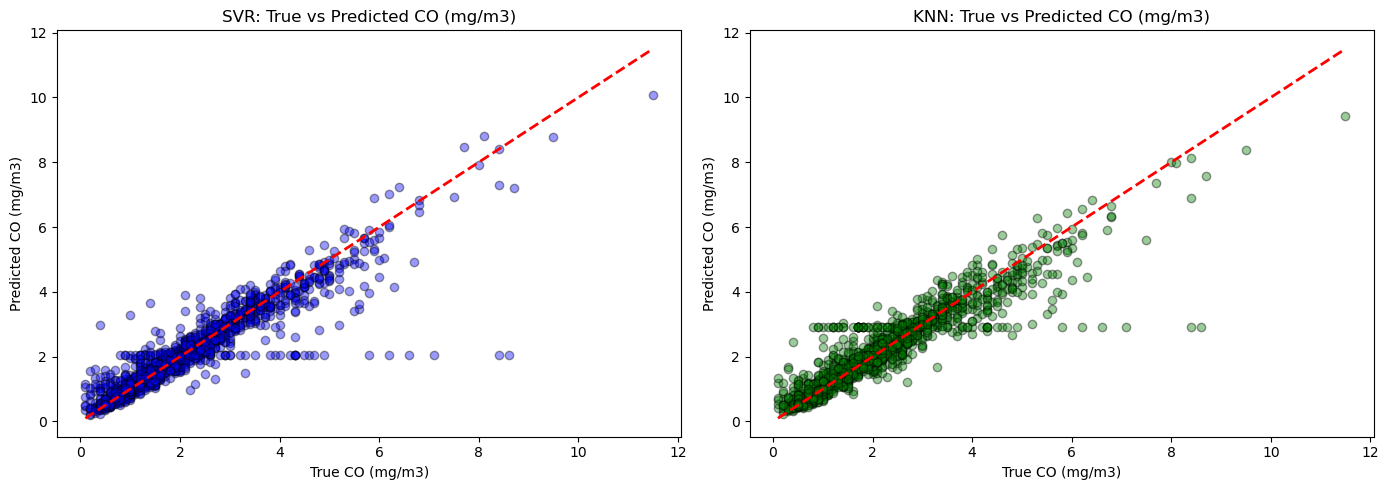

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# SVR Predictions vs True
y_pred_svr = best_svr_model.predict(X_test_D)
ax[0].scatter(y_test_D, y_pred_svr, alpha=0.4, color='blue', edgecolor='k')
ax[0].plot([y_test_D.min(), y_test_D.max()], [y_test_D.min(), y_test_D.max()], 'r--', lw=2)
ax[0].set_title("SVR: True vs Predicted CO (mg/m3)")
ax[0].set_xlabel("True CO (mg/m3)")
ax[0].set_ylabel("Predicted CO (mg/m3)")

# KNN Predictions vs True
y_pred_knn = best_knn_model.predict(X_test_D)
ax[1].scatter(y_test_D, y_pred_knn, alpha=0.4, color='green', edgecolor='k')
ax[1].plot([y_test_D.min(), y_test_D.max()], [y_test_D.min(), y_test_D.max()], 'r--', lw=2)
ax[1].set_title("KNN: True vs Predicted CO (mg/m3)")
ax[1].set_xlabel("True CO (mg/m3)")
ax[1].set_ylabel("Predicted CO (mg/m3)")

plt.tight_layout()
plt.show()

Part 6: Conclusion

In [58]:
import pandas as pd
from IPython.display import display, Markdown

# 1. Using Pandas to create a tabular structure representing the leaderboard
leaderboard_df = pd.DataFrame(results_D).sort_values(by="RMSE").reset_index(drop=True)
leaderboard_df.index += 1  # 1-indexed rank

# 2. Top Metrics
best_model = leaderboard_df.iloc[0]
runner_up = leaderboard_df.iloc[1]

best_model_name = best_model["Model"]
best_rmse = best_model["RMSE"]
best_r2 = best_model["R2"]

# 3. Displaying the table
print("Results")
display(leaderboard_df.style.highlight_min(subset=["RMSE", "MAE"], color="lightgreen", axis=0)
                            .highlight_max(subset=["R2"], color="lightgreen", axis=0)
                            .format({"RMSE": "{:.4f}", "MAE": "{:.4f}", "R2": "{:.4f}"}))

# 4. End statement
print(f"\n{best_model_name} performs best with RMSE = {best_rmse:.4f} and R2 = {best_r2:.4f}.")

Results


,Model,RMSE,MAE,R2
1,KNN Regressor,0.5331,0.3089,0.8636
2,SVR (RBF Kernel),0.5499,0.2887,0.8548



KNN Regressor performs best with RMSE = 0.5331 and R2 = 0.8636.


### D.2 SVR under the shared protocol
M4's exploration above used a random split, 8 features and test-set scores. For the group comparison, SVR is re-tuned with **the same protocol as every other model**: all 12 features, the chronological split, `TimeSeriesSplit(5)` and the shared metrics. This gives training scores beside validation scores. The grid is centred on M4's best settings (C ≈ 9.5, ε = 0.05, γ = 'scale').

In [59]:
from sklearn.svm import SVR

svr_shared_pipe = Pipeline([("prep", make_preprocessor(scale=True)),
                            ("model", SVR(kernel="rbf", cache_size=1000))])
svr_shared_grid = {
    "model__C": [1, 3, 10, 30],
    "model__gamma": ["scale", 0.03, 0.1],
    "model__epsilon": [0.05, 0.1],
}
svr_shared_gs, svr_shared_res = run_search("SVR (RBF)", svr_shared_pipe, svr_shared_grid)
svr_shared_res

model                                                      SVR (RBF)
train_MAE                                                    0.17751
val_MAE                                                     0.365832
val_MAE_std                                                 0.145979
train_R2                                                    0.956854
val_R2                                                      0.834249
train_within_%                                              93.52593
val_within_%                                               79.824047
mean_fit_time_s                                             0.487829
best_params        {'model__C': 1, 'model__epsilon': 0.05, 'model...
overfit_gap_MAE                                             0.188322
dtype: object

### D.3 KNN under the shared protocol
Same protocol as above. The grid is centred on M4's best settings (k = 7, distance weighting, Manhattan distance).

In [60]:
from sklearn.neighbors import KNeighborsRegressor

knn_shared_pipe = Pipeline([("prep", make_preprocessor(scale=True)),
                            ("model", KNeighborsRegressor())])
knn_shared_grid = {
    "model__n_neighbors": [5, 7, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_shared_gs, knn_shared_res = run_search("KNN", knn_shared_pipe, knn_shared_grid)
knn_shared_res

model                                                            KNN
train_MAE                                                   0.002082
val_MAE                                                     0.432584
val_MAE_std                                                 0.148857
train_R2                                                    0.999197
val_R2                                                      0.797147
train_within_%                                             99.841677
val_within_%                                               71.788856
mean_fit_time_s                                             0.011123
best_params        {'model__n_neighbors': 15, 'model__p': 1, 'mod...
overfit_gap_MAE                                             0.430503
dtype: object

## Part E — M1: overfitting analysis
Learning curves, per-fold scores over time, residuals over time. Runs once the model owners send their best params.


### E.1 Learning curve
Training vs validation MAE as the amount of training data grows. If the gap stays large, the model is overfitting. If both errors are high, it is underfitting.

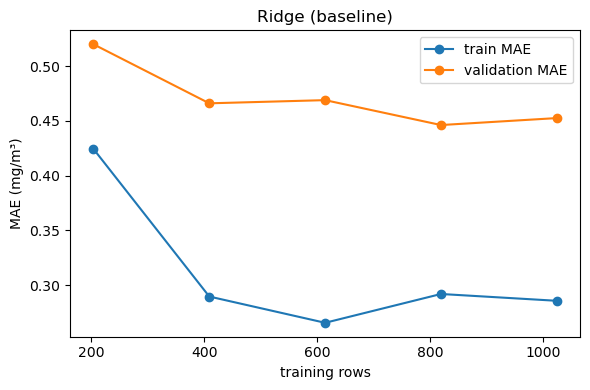

In [61]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(name, pipe, ax):
    sizes, tr, va = learning_curve(pipe, X_train, y_train, cv=CV, scoring="neg_mean_absolute_error",
                                   train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)
    ax.plot(sizes, -tr.mean(1), "o-", label="train MAE")
    ax.plot(sizes, -va.mean(1), "o-", label="validation MAE")
    ax.set_title(name); ax.set_xlabel("training rows"); ax.set_ylabel("MAE (mg/m³)"); ax.legend()

fig, ax = plt.subplots(figsize=(6, 4))
plot_learning_curve("Ridge (baseline)", ridge_gs.best_estimator_, ax)
plt.tight_layout(); plt.show()

### E.2 Validation score per fold over time
% within tolerance for each time fold. The drop in the later (winter) folds shows that much of the error comes from drift over time, not only from overfitting.

In [62]:
# Per-fold validation score: shows whether the error comes from overfitting or from drift over time
def per_fold(name, gs):
    r, i = gs.cv_results_, gs.best_index_
    return pd.Series({f"fold{k+1}": r[f"split{k}_test_within"][i] for k in range(CV.n_splits)}, name=name)

pd.DataFrame([per_fold("Ridge (baseline)", ridge_gs)]).round(1)

,fold1,fold2,fold3,fold4,fold5
Ridge (baseline),81.8,88.5,76.1,55.5,61.0


### E.3 Collect the best tuned model of every family
For Random Forest, M2 tried three variants. The one with the lowest validation MAE represents the family. All results below come from the same folds and metrics.

In [63]:
rf_candidates = {
    "Random Forest (Regularised)": rf_gs_reg,
    "Random Forest (Improved)": rf_gs_improved,
    "Random Forest (Log Target)": rf_log_gs,
}
rf_name, rf_best_gs = max(rf_candidates.items(), key=lambda kv: kv[1].best_score_)   # best_score_ = -MAE
print("Random Forest variant used for the comparison:", rf_name)

FINAL_SEARCHES = {
    "Linear Regression": lin_gs,
    "Ridge": ridge_gs,
    "Random Forest": rf_best_gs,
    "HistGradientBoosting": hgb_search,
    "SVR (RBF)": svr_shared_gs,
    "KNN": knn_shared_gs,
}

def summarise(name, gs):
    r, i = gs.cv_results_, gs.best_index_
    return {"model": name,
            "train_MAE": -r["mean_train_mae"][i], "val_MAE": -r["mean_test_mae"][i],
            "val_MAE_std": r["std_test_mae"][i],
            "overfit_gap_MAE": r["mean_train_mae"][i] - r["mean_test_mae"][i],
            "train_R2": r["mean_train_r2"][i], "val_R2": r["mean_test_r2"][i],
            "train_within_%": r["mean_train_within"][i], "val_within_%": r["mean_test_within"][i],
            "best_params": gs.best_params_}

cv_table = pd.DataFrame([summarise(n, g) for n, g in FINAL_SEARCHES.items()]).set_index("model")
pd.set_option("display.max_colwidth", 120)
display(cv_table.drop(columns="best_params").round(3))
cv_table[["best_params"]]

Random Forest variant used for the comparison: Random Forest (Improved)


,train_MAE,val_MAE,val_MAE_std,overfit_gap_MAE,train_R2,val_R2,train_within_%,val_within_%
model,,,,,,,,
Linear Regression,0.255,0.450,0.120,0.196,0.928,0.789,88.007,68.583
Ridge,0.283,0.430,0.151,0.147,0.913,0.806,84.967,72.571
Random Forest,0.087,0.369,0.164,0.282,0.989,0.827,98.869,79.218
HistGradientBoosting,0.164,0.360,0.176,0.196,0.967,0.830,95.393,80.821
SVR (RBF),0.178,0.366,0.146,0.188,0.957,0.834,93.526,79.824
KNN,0.002,0.433,0.149,0.431,0.999,0.797,99.842,71.789


,best_params
model,
Linear Regression,{}
Ridge,{'model__alpha': 316.22776601683796}
Random Forest,"{'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}"
HistGradientBoosting,"{'model__l2_regularization': 0.5, 'model__learning_rate': 0.05, 'model__max_iter': 100, 'model__max_leaf_nodes': 15}"
SVR (RBF),"{'model__C': 1, 'model__epsilon': 0.05, 'model__gamma': 0.03}"
KNN,"{'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}"


### E.4 Overfitting gap: training vs validation MAE
A large gap between training and validation error means the model memorises the training window rather than generalising to the next time block.

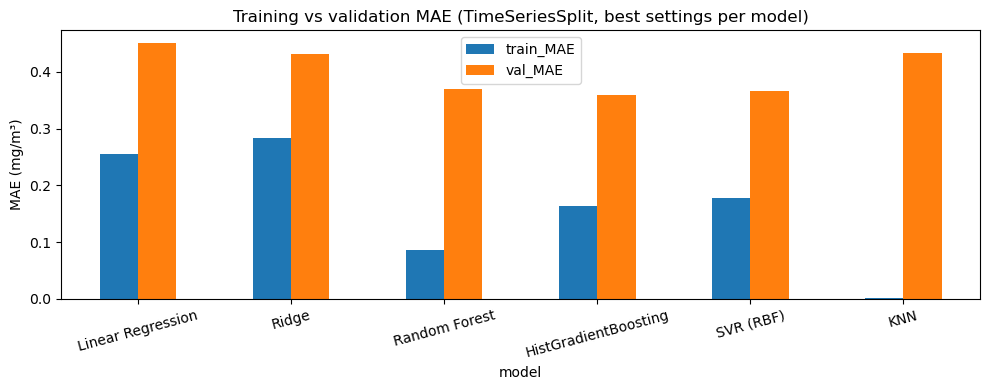

In [64]:
ax = cv_table[["train_MAE", "val_MAE"]].plot.bar(figsize=(10, 4), rot=15)
ax.set_ylabel("MAE (mg/m³)")
ax.set_title("Training vs validation MAE (TimeSeriesSplit, best settings per model)")
plt.tight_layout(); plt.savefig("fig_overfitting_gap.png", dpi=200); plt.show()

### E.5 Validation score per fold over time, for all models
If every model drops in the same folds, the cause is a change in the data over time (sensor drift, season), not overfitting by one model.

,F1 May 04-Jun 04,F2 Jun 04-Aug 04,F3 Aug 04-Oct 04,F4 Oct 04-Dec 04,F5 Dec 04-Jan 05
Linear Regression,83.3,63.2,71.6,61.9,63.0
Ridge,81.8,88.5,76.1,55.5,61.0
Random Forest,80.5,92.4,87.2,76.6,59.3
HistGradientBoosting,83.8,92.4,89.2,80.1,58.7
SVR (RBF),80.2,92.1,85.4,76.3,65.1
KNN,76.8,82.6,78.9,64.0,56.6


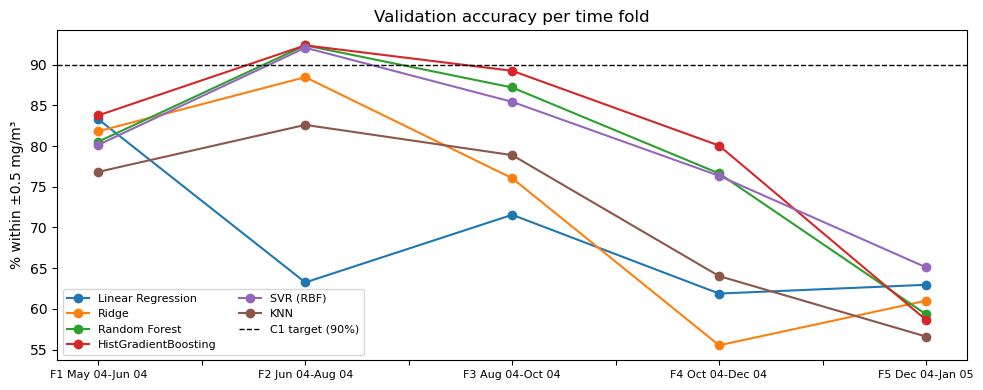

In [65]:
fold_dates = [f"F{k+1} {train_df.datetime.iloc[va[0]]:%b %y}-{train_df.datetime.iloc[va[-1]]:%b %y}"
              for k, (tr, va) in enumerate(CV.split(X_train))]
fold_table = pd.DataFrame([per_fold(n, g) for n, g in FINAL_SEARCHES.items()])
fold_table.columns = fold_dates
display(fold_table.round(1))

ax = fold_table.T.plot(marker="o", figsize=(10, 4))
ax.axhline(TARGET_PCT, ls="--", c="k", lw=1, label="C1 target (90%)")
ax.set_ylabel("% within ±0.5 mg/m³"); ax.set_title("Validation accuracy per time fold")
ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("fig_per_fold.png", dpi=200); plt.show()

### E.6 Learning curves for all models
Training and validation MAE as the training window grows. If the curves converge, more data would not help much. If validation error keeps falling, the model is data-limited.

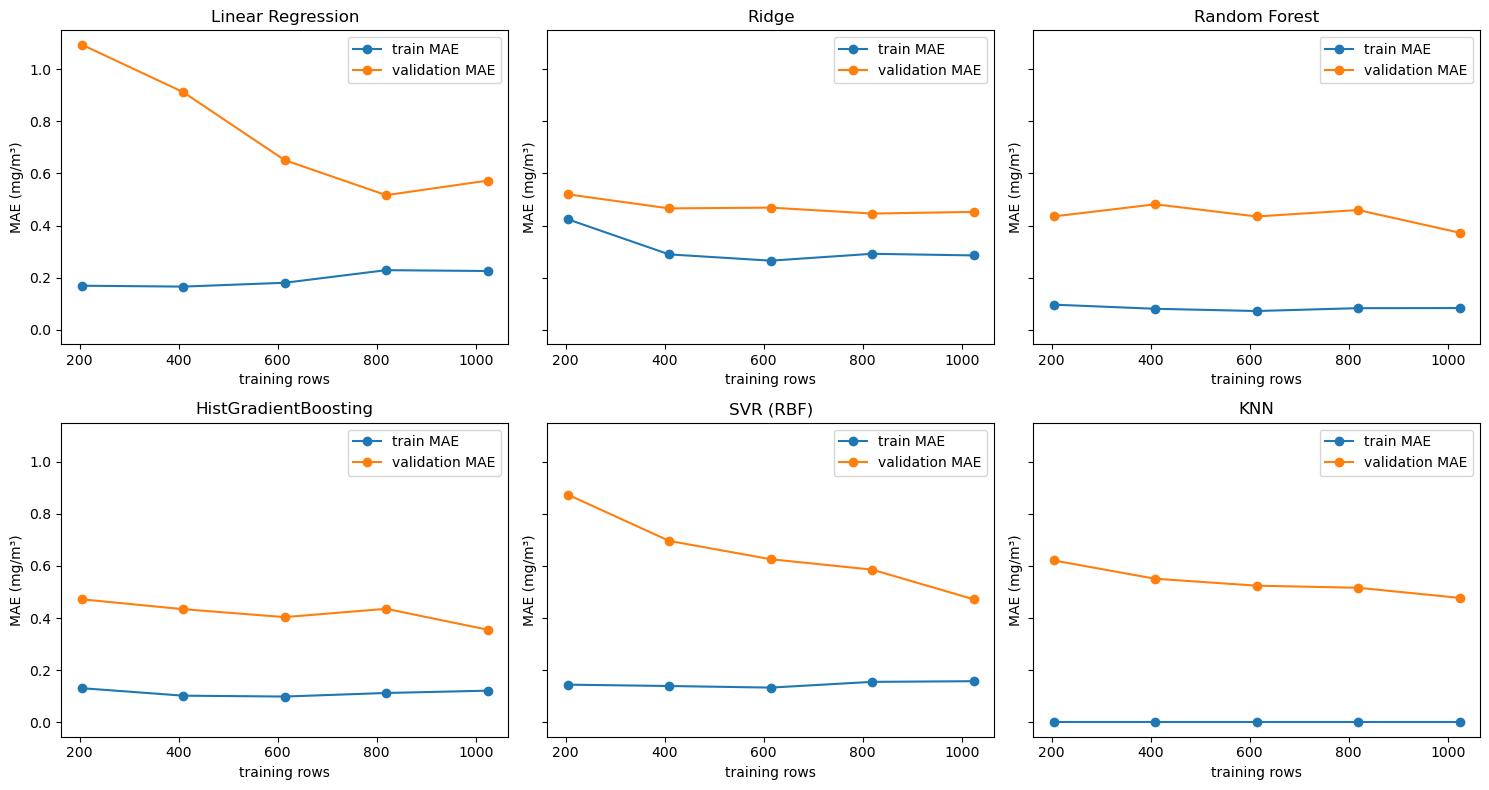

In [66]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, (name, gs) in zip(axes.ravel(), FINAL_SEARCHES.items()):
    plot_learning_curve(name, gs.best_estimator_, ax)
plt.tight_layout(); plt.savefig("fig_learning_curves.png", dpi=200); plt.show()

## Part F–G — M5: initial benchmark (single hold-out, default settings)

> **Note:** this benchmark scores the test set during the owner's own exploration. It is **not** used for model selection. The group's single official test score is in **Part H.6**.


Evaluating Linear Regression...

Evaluating Random Forest...



Evaluating Gradient Boosting...



Evaluating SVR...



========== MODEL COMPARISON ==========
            Model  Train R2  Validation R2  Train MAE  Validation MAE  R2 Gap  Training Time (s)  Prediction Time (ms/sample)
    Random Forest    0.9918         0.5975     0.0782          0.6054  0.3943             3.1224                       0.0477
Linear Regression    0.9077         0.6149     0.2996          0.6062  0.2928             0.0088                       0.0016
Gradient Boosting    0.9780         0.5733     0.1445          0.6316  0.4046             0.3254                       0.0053
              SVR    0.9831         0.4732     0.1179          0.7702  0.5099            19.0493                       0.2195


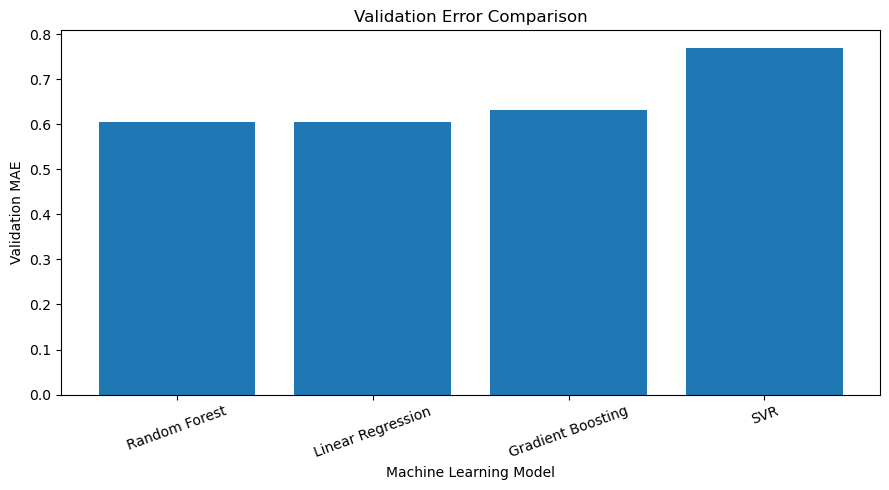

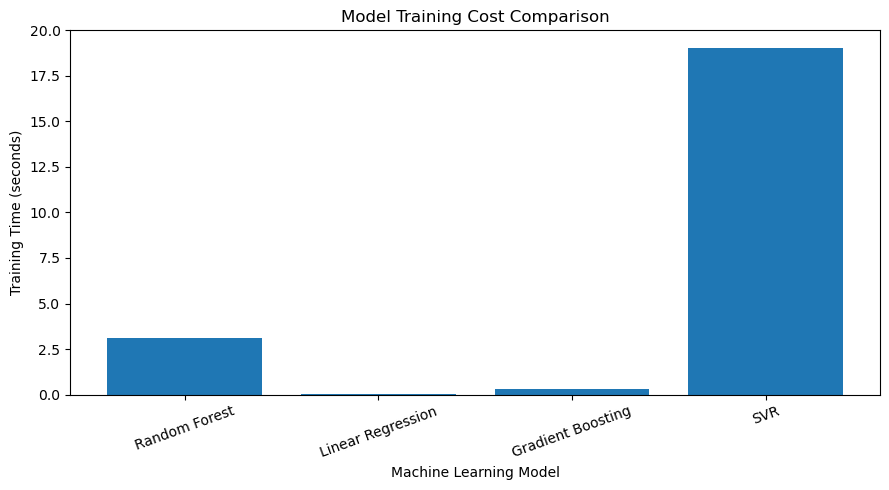

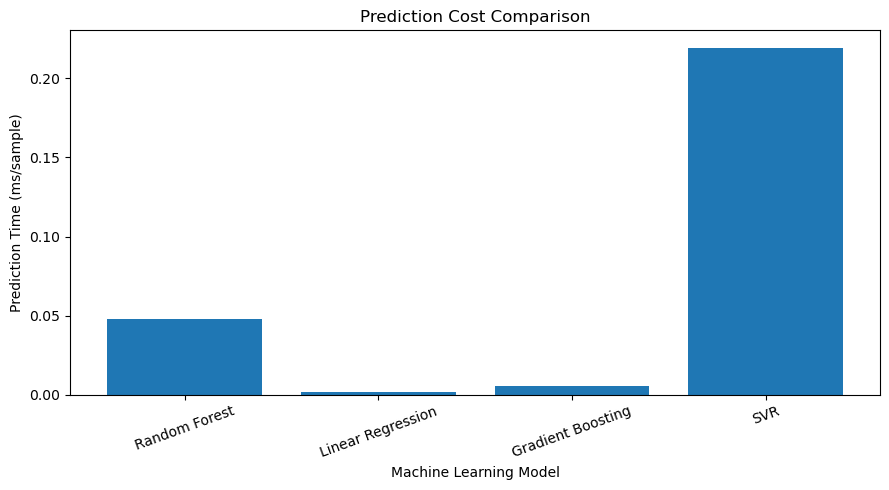


========== CONSTRAINT CHECK ==========
            Model  Validation MAE  Meets Constraints
    Random Forest        0.605364               True
Linear Regression        0.606165               True
Gradient Boosting        0.631583               True
              SVR        0.770248               True

========== SELECTED MODEL ==========
Best Model: Random Forest

========== FINAL TEST RESULTS ==========
Selected Model: Random Forest
Test R2: 0.7523
Test MAE: 0.4165
Prediction Time (s): 0.059736

M5 evaluation completed.


In [67]:
# M5 - TESTING AND COST LEAD
# Air Quality Dataset - Regression Model Comparison
# ------------------------------------------------------------
# 1. Build validation split from the training window only
# ------------------------------------------------------------

import time
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Keep the original train/test split untouched for the final evaluation.
# Use the tail of the training set as a validation set for model selection.
val_size = max(1, int(len(X_train) * 0.2))
X_train_fit = X_train.iloc[:-val_size].copy()
y_train_fit = y_train.iloc[:-val_size].copy()
X_val = X_train.iloc[-val_size:].copy()
y_val = y_train.iloc[-val_size:].copy()

model_m1 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

model_m2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
])

model_m3 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))
])

model_m4 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVR(kernel="rbf", C=100.0, epsilon=0.1))
])

# Make the model dictionary match the testing.py contract
models = {
    "Linear Regression": model_m1,
    "Random Forest": model_m2,
    "Gradient Boosting": model_m3,
    "SVR": model_m4,
}

# ------------------------------------------------------------
# 2. MODEL BENCHMARKING
# ------------------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nEvaluating {name}...")

    current_model = clone(model)

    start = time.perf_counter()
    current_model.fit(X_train_fit, y_train_fit)
    training_time = time.perf_counter() - start

    train_pred = current_model.predict(X_train_fit)
    val_pred = current_model.predict(X_val)

    current_model.predict(X_val)
    prediction_times = []
    for _ in range(10):
        start = time.perf_counter()
        current_model.predict(X_val)
        elapsed = time.perf_counter() - start
        prediction_times.append(elapsed)

    prediction_time = np.median(prediction_times)
    prediction_ms = (prediction_time / len(X_val)) * 1000

    train_r2 = r2_score(y_train_fit, train_pred)
    val_r2 = r2_score(y_val, val_pred)
    train_mae = mean_absolute_error(y_train_fit, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)
    r2_gap = train_r2 - val_r2

    results.append({
        "Model": name,
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "R2 Gap": r2_gap,
        "Training Time (s)": training_time,
        "Prediction Time (ms/sample)": prediction_ms,
    })

    trained_models[name] = current_model

# ------------------------------------------------------------
# 3. MODEL COMPARISON TABLE
# ------------------------------------------------------------

comparison = pd.DataFrame(results)
comparison = comparison.sort_values(by="Validation MAE", ascending=True).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
print(comparison.round(4).to_string(index=False))
comparison.to_csv("M5_Model_Comparison.csv", index=False)

# ------------------------------------------------------------
# 4. PERFORMANCE VISUALISATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Validation MAE"])
plt.xlabel("Machine Learning Model")
plt.ylabel("Validation MAE")
plt.title("Validation Error Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Training Time (s)"])
plt.xlabel("Machine Learning Model")
plt.ylabel("Training Time (seconds)")
plt.title("Model Training Cost Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Prediction Time (ms/sample)"])
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Time (ms/sample)")
plt.title("Prediction Cost Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. CHECK COMPUTATIONAL CONSTRAINTS
# ------------------------------------------------------------

MAX_TRAIN_TIME = None
MAX_PREDICTION_MS = None

comparison["Meets Constraints"] = True
if MAX_TRAIN_TIME is not None:
    comparison["Meets Constraints"] &= (comparison["Training Time (s)"] <= MAX_TRAIN_TIME)
if MAX_PREDICTION_MS is not None:
    comparison["Meets Constraints"] &= (comparison["Prediction Time (ms/sample)"] <= MAX_PREDICTION_MS)

print("\n========== CONSTRAINT CHECK ==========")
print(comparison[["Model", "Validation MAE", "Meets Constraints"]].to_string(index=False))

# ------------------------------------------------------------
# 6. SELECT THE BEST MODEL
# ------------------------------------------------------------

eligible = comparison[comparison["Meets Constraints"]]
if eligible.empty:
    raise ValueError("No model meets the specified constraints.")

selected_name = eligible.sort_values("Validation MAE").iloc[0]["Model"]
final_model = trained_models[selected_name]

print("\n========== SELECTED MODEL ==========")
print("Best Model:", selected_name)

# ------------------------------------------------------------
# 7. FINAL TEST EVALUATION
# ------------------------------------------------------------
# The untouched test split is evaluated only once after model choice.

start = time.perf_counter()
test_pred = final_model.predict(X_test)
test_time = time.perf_counter() - start

test_r2 = r2_score(y_test, test_pred)
test_mae = mean_absolute_error(y_test, test_pred)

print("\n========== FINAL TEST RESULTS ==========")
print("Selected Model:", selected_name)
print("Test R2:", round(test_r2, 4))
print("Test MAE:", round(test_mae, 4))
print("Prediction Time (s):", round(test_time, 6))

# ------------------------------------------------------------
# 8. SAVE FINAL RESULTS
# ------------------------------------------------------------

final_results = pd.DataFrame([{
    "Selected Model": selected_name,
    "Test R2": test_r2,
    "Test MAE": test_mae,
    "Test Prediction Time (s)": test_time,
}])
final_results.to_csv("M5_Final_Test_Results.csv", index=False)
comparison.to_csv("M5_Model_Comparison.csv", index=False)

print("\nM5 evaluation completed.")


## Part H — Final comparison under one protocol: cost, constraints, recommendation and the single test score
Every model here comes from the same split, folds and metrics (Parts A–E). Costs are re-measured **single-threaded** (`n_jobs=1`, and OpenMP/BLAS threads limited to 1), so the timings compare like with like.

### H.1 Computational cost of each tuned pipeline
- **Fit time:** median of 3 fits on the full training window.
- **Batch latency:** median time per sample when predicting 1,000 rows. This is the C2 measure.
- **Single-row latency:** median time to predict one hourly reading, including scikit-learn's per-call overhead.
- **Model size:** the pickled pipeline, in KB.

In [68]:
import time, pickle
from sklearn.base import clone
from threadpoolctl import threadpool_limits

def single_thread(est):
    est = clone(est)
    for p in est.get_params():
        if p.endswith("n_jobs"):
            est.set_params(**{p: 1})
    return est

def measure_cost(est, n_fit=3, n_pred=7, n_single=200):
    fit_t = []
    for _ in range(n_fit):
        m = single_thread(est)
        t0 = time.perf_counter(); m.fit(X_train, y_train); fit_t.append(time.perf_counter() - t0)
    X_batch = X_train.iloc[-1000:]
    pred_t = []
    for _ in range(n_pred):
        t0 = time.perf_counter(); m.predict(X_batch); pred_t.append(time.perf_counter() - t0)
    X_one = X_train.iloc[[-1]]
    m.predict(X_one)
    one_t = []
    for _ in range(n_single):
        t0 = time.perf_counter(); m.predict(X_one); one_t.append(time.perf_counter() - t0)
    return {"fit_time_s": np.median(fit_t),
            "batch_ms_per_sample": 1000 * np.median(pred_t) / len(X_batch),
            "single_row_ms": 1000 * np.median(one_t),
            "model_size_KB": len(pickle.dumps(m)) / 1024}

with threadpool_limits(limits=1):
    cost_table = pd.DataFrame({n: measure_cost(g.best_estimator_) for n, g in FINAL_SEARCHES.items()}).T

print("Runtime:", RUNTIME, "| all timings single-threaded")
cost_table.round(4)

Runtime: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel | 12 CPU cores | Python 3.12.7 | all timings single-threaded


,fit_time_s,batch_ms_per_sample,single_row_ms,model_size_KB
Linear Regression,0.0106,0.0022,1.6528,2.6875
Ridge,0.0100,0.0031,1.6314,2.6445
Random Forest,22.8412,0.0867,24.0680,137342.0586
HistGradientBoosting,0.2339,0.0095,1.7899,191.2969
SVR (RBF),1.3640,0.3883,2.0995,515.8994
KNN,0.0166,0.0516,1.9859,730.3545


### H.2 Scalability: fit time vs training-set size
Each model is fitted on 25 %, 50 %, 75 % and 100 % of the training window (single-threaded). The growth exponent *b* in fit time ∝ n^b shows how training cost grows with data (b ≈ 1 is linear, b ≈ 2 is quadratic).

,1534,3069,4604,6139,growth_exponent_b
Linear Regression,0.0073,0.0082,0.0145,0.0109,0.3980
Ridge,0.0069,0.0083,0.0095,0.0104,0.2986
Random Forest,4.9939,10.5782,16.5129,22.6288,1.0896
HistGradientBoosting,0.1943,0.1834,0.1936,0.2047,0.0329
SVR (RBF),0.0975,0.3526,0.7928,1.3829,1.9142
KNN,0.0074,0.0102,0.0137,0.0163,0.5710


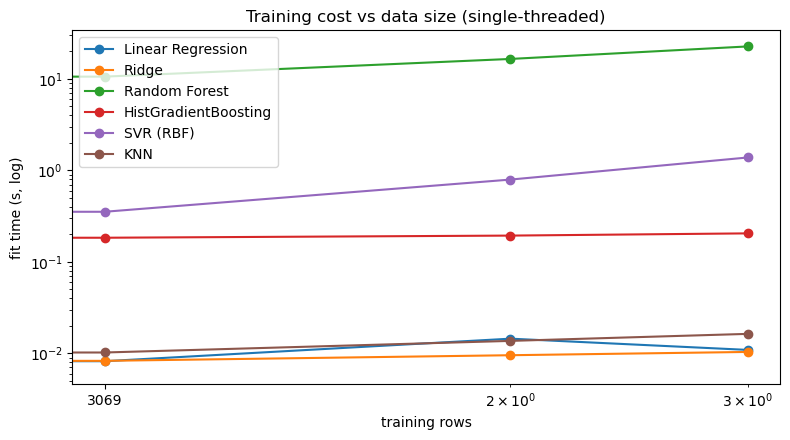

In [69]:
fractions = [0.25, 0.5, 0.75, 1.0]
scal = {}
with threadpool_limits(limits=1):
    for name, gs in FINAL_SEARCHES.items():
        row = {}
        for f in fractions:
            k = int(len(X_train) * f)
            m = single_thread(gs.best_estimator_)
            t0 = time.perf_counter(); m.fit(X_train.iloc[:k], y_train.iloc[:k])
            row[k] = time.perf_counter() - t0
        scal[name] = row
scal_table = pd.DataFrame(scal).T
sizes = np.array(scal_table.columns, dtype=float)
scal_table["growth_exponent_b"] = [np.polyfit(np.log(sizes), np.log(r.values.astype(float)), 1)[0]
                                   for _, r in scal_table.iterrows()]
display(scal_table.round(4))

ax = scal_table.drop(columns="growth_exponent_b").T.plot(marker="o", logx=True, logy=True, figsize=(8, 4.5))
ax.set_xlabel("training rows"); ax.set_ylabel("fit time (s, log)"); ax.set_title("Training cost vs data size (single-threaded)")
plt.tight_layout(); plt.savefig("fig_scalability.png", dpi=200); plt.show()

### H.3 Main comparison table: accuracy, overfitting, cost and constraints
This is the table for report §3. C1 and C2 are checked on **validation** results only. The test set has not been used for any decision so far.

In [70]:
main_table = cv_table[["train_MAE", "val_MAE", "val_MAE_std", "overfit_gap_MAE", "val_R2",
                       "train_within_%", "val_within_%"]].join(cost_table)
main_table["meets_C1 (val >=90%)"] = main_table["val_within_%"] >= TARGET_PCT
main_table["meets_C2 (<=1 ms)"] = main_table["batch_ms_per_sample"] <= LATENCY_LIMIT_MS
main_table.round(4).to_csv("main_comparison_table.csv")
main_table.round(3)

,train_MAE,val_MAE,val_MAE_std,overfit_gap_MAE,val_R2,train_within_%,val_within_%,fit_time_s,batch_ms_per_sample,single_row_ms,model_size_KB,meets_C1 (val >=90%),meets_C2 (<=1 ms)
model,,,,,,,,,,,,,
Linear Regression,0.255,0.450,0.120,0.196,0.789,88.007,68.583,0.011,0.002,1.653,2.688,False,True
Ridge,0.283,0.430,0.151,0.147,0.806,84.967,72.571,0.010,0.003,1.631,2.645,False,True
Random Forest,0.087,0.369,0.164,0.282,0.827,98.869,79.218,22.841,0.087,24.068,137342.059,False,True
HistGradientBoosting,0.164,0.360,0.176,0.196,0.830,95.393,80.821,0.234,0.009,1.790,191.297,False,True
SVR (RBF),0.178,0.366,0.146,0.188,0.834,93.526,79.824,1.364,0.388,2.100,515.899,False,True
KNN,0.002,0.433,0.149,0.431,0.797,99.842,71.789,0.017,0.052,1.986,730.354,False,True


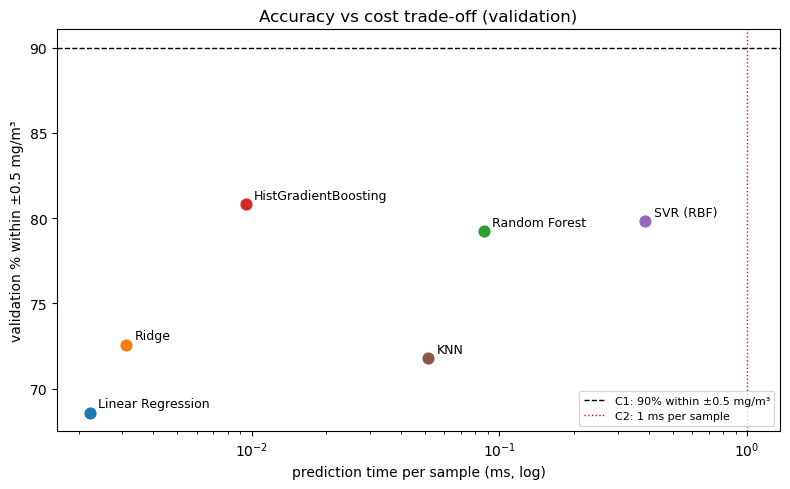

In [71]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, r in main_table.iterrows():
    ax.scatter(r["batch_ms_per_sample"], r["val_within_%"], s=60)
    ax.annotate(name, (r["batch_ms_per_sample"], r["val_within_%"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log")
ax.axhline(TARGET_PCT, ls="--", c="k", lw=1, label="C1: 90% within ±0.5 mg/m³")
ax.axvline(LATENCY_LIMIT_MS, ls=":", c="r", lw=1, label="C2: 1 ms per sample")
ax.set_xlabel("prediction time per sample (ms, log)"); ax.set_ylabel("validation % within ±0.5 mg/m³")
ax.set_title("Accuracy vs cost trade-off (validation)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("fig_tradeoff.png", dpi=200); plt.show()

### H.4 Selection rule, applied to validation results only
1. Keep the models that meet C2 (latency).
2. If any of them meets C1, pick the **cheapest** one that does.
3. If none meets C1, pick the model **closest to C1** (highest validation % within). Ties are broken by lower validation MAE.

In [72]:
eligible = main_table[main_table["meets_C2 (<=1 ms)"]]
meets_both = eligible[eligible["meets_C1 (val >=90%)"]]
if len(meets_both):
    chosen = meets_both.sort_values("batch_ms_per_sample").index[0]
    rule = "cheapest model meeting both C1 and C2 on validation"
else:
    chosen = eligible.sort_values(["val_within_%", "val_MAE"], ascending=[False, True]).index[0]
    rule = "no model meets C1 on validation -> model closest to C1 among those meeting C2"

print("Rule applied :", rule)
print("Recommended  :", chosen)
print("Settings     :", FINAL_SEARCHES[chosen].best_params_)
main_table.loc[[chosen]].round(3)

Rule applied : no model meets C1 on validation -> model closest to C1 among those meeting C2
Recommended  : HistGradientBoosting
Settings     : {'model__l2_regularization': 0.5, 'model__learning_rate': 0.05, 'model__max_iter': 100, 'model__max_leaf_nodes': 15}


,train_MAE,val_MAE,val_MAE_std,overfit_gap_MAE,val_R2,train_within_%,val_within_%,fit_time_s,batch_ms_per_sample,single_row_ms,model_size_KB,meets_C1 (val >=90%),meets_C2 (<=1 ms)
model,,,,,,,,,,,,,
HistGradientBoosting,0.164,0.36,0.176,0.196,0.83,95.393,80.821,0.234,0.009,1.79,191.297,False,True


### H.5 Recommended pipeline
The chosen pipeline is the `best_estimator_` from its grid search. GridSearchCV has already refitted it on the **full** training window (Mar 2004 – Jan 2005) with the selected settings.

In [73]:
final_pipe = FINAL_SEARCHES[chosen].best_estimator_
final_pipe

Pipeline(steps=[('model',
                 HistGradientBoostingRegressor(l2_regularization=0.5,
                                               learning_rate=0.05,
                                               max_leaf_nodes=15,
                                               random_state=42))])

### H.6 Final test score: computed ONCE
This is the only place in the group's protocol where the test window (Jan – Apr 2005) is used for the recommendation.

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_test = final_pipe.predict(X_test)
test_scores = pd.Series({
    "test_MAE": mean_absolute_error(y_test, y_pred_test),
    "test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred_test)),
    "test_R2": r2_score(y_test, y_pred_test),
    "test_within_%": pct_within(y_test, y_pred_test),
}, name=chosen)
test_scores["meets_C1 (test)"] = test_scores["test_within_%"] >= TARGET_PCT
test_scores["meets_C2"] = bool(main_table.loc[chosen, "meets_C2 (<=1 ms)"])

print(f"Recommended: {chosen}  (test window {test_df.datetime.min():%Y-%m-%d} -> {test_df.datetime.max():%Y-%m-%d}, {len(X_test)} rows)")
test_scores.to_frame().T.to_csv("final_test_scores.csv", index=False)
test_scores

Recommended: HistGradientBoosting  (test window 2005-01-29 -> 2005-04-04, 1535 rows)


test_MAE            0.350283
test_RMSE            0.56997
test_R2              0.82029
test_within_%      79.869707
meets_C1 (test)        False
meets_C2                True
Name: HistGradientBoosting, dtype: object

### H.7 Where the recommended model misses C1 on the test window
Errors are grouped by true CO level and by month. This shows *why* the constraint is or is not met, and what would change the recommendation.

,rows,MAE,within_pct
actual,,,
"(0, 1]",413,0.26,86.68
"(1, 2]",525,0.23,92.57
"(2, 3]",313,0.37,76.68
"(3, 5]",222,0.58,53.60
"(5, 12]",62,1.09,37.10


,rows,MAE,within_pct
datetime,,,
2005-01,63,0.26,95.24
2005-02,663,0.41,76.02
2005-03,724,0.32,80.25
2005-04,85,0.19,95.29


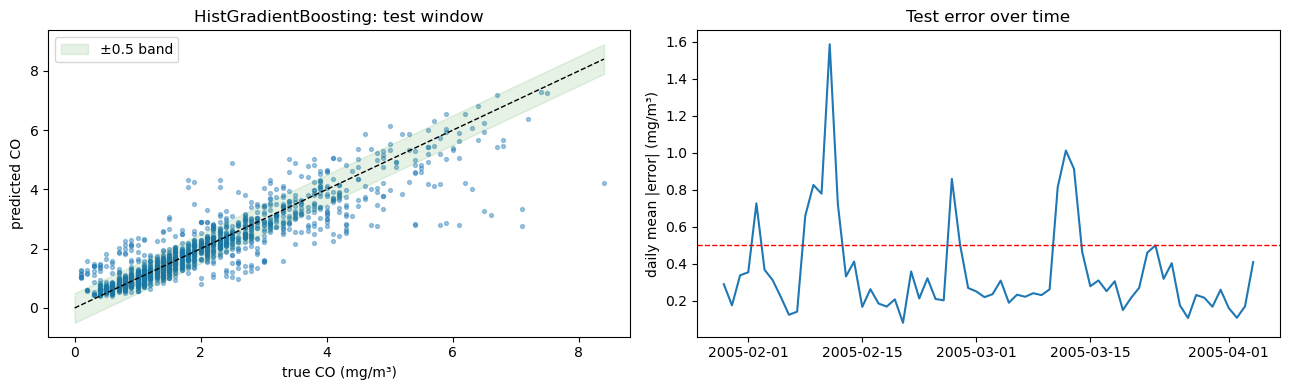

In [75]:
err = pd.DataFrame({"datetime": test_df["datetime"].values, "actual": y_test.values, "pred": y_pred_test})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["within"] = err["abs_err"] <= TOLERANCE

by_level = err.groupby(pd.cut(err["actual"], [0, 1, 2, 3, 5, 12]), observed=True).agg(
    rows=("within", "size"), MAE=("abs_err", "mean"), within_pct=("within", lambda s: 100 * s.mean()))
by_month = err.groupby(err["datetime"].dt.to_period("M")).agg(
    rows=("within", "size"), MAE=("abs_err", "mean"), within_pct=("within", lambda s: 100 * s.mean()))
display(by_level.round(2)); display(by_month.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(err["actual"], err["pred"], s=8, alpha=0.4)
lim = [0, float(err[["actual", "pred"]].max().max())]
ax[0].plot(lim, lim, "k--", lw=1)
ax[0].fill_between(lim, [l - TOLERANCE for l in lim], [l + TOLERANCE for l in lim], color="g", alpha=0.1, label="±0.5 band")
ax[0].set_xlabel("true CO (mg/m³)"); ax[0].set_ylabel("predicted CO"); ax[0].set_title(f"{chosen}: test window"); ax[0].legend()
daily_err = err.set_index("datetime")["abs_err"].resample("D").mean()
ax[1].plot(daily_err.index, daily_err.values); ax[1].axhline(TOLERANCE, ls="--", c="r", lw=1)
ax[1].set_ylabel("daily mean |error| (mg/m³)"); ax[1].set_title("Test error over time")
plt.tight_layout(); plt.savefig("fig_test_errors.png", dpi=200); plt.show()

## Key findings (numbers from the outputs above)

**Accuracy and overfitting (validation, `TimeSeriesSplit(5)`).** The three non-linear models are close: HistGradientBoosting has MAE 0.360 and 80.8% within ±0.5, SVR 0.366 and 79.8%, and Random Forest 0.369 and 79.2%. All three clearly beat the linear reference (Ridge 0.430, 72.6%). KNN overfits most (train MAE 0.002 vs val 0.433), followed by Random Forest (gap 0.28). HistGradientBoosting and SVR have gaps similar to Ridge.

**No model meets C1 (90% within ±0.5 mg/m³).** Every model drops to roughly 57–65% in the Dec 2004 – Jan 2005 fold (E.5). Because all models fail in the same fold, the cause is drift over time and higher winter CO, not one model overfitting.

**Cost (single-threaded).** All models meet C2 for batch prediction (≤ 1 ms per sample). They differ hugely in training cost and size:
- Random Forest: about 23 s to fit, a pickle of about 134 MB, and roughly 24 ms per single-row call.
- HistGradientBoosting: about 0.23 s to fit and about 190 KB, with fit time almost flat as data grows.
- SVR: fit time grows about quadratically with the training rows (b ≈ 1.9), so it scales worst.

**Recommendation.** HistGradientBoosting has the best validation accuracy, low cost, a small model and moderate overfitting. On the test window (Jan – Apr 2005), scored once: MAE 0.350, R² 0.820, 79.9% within ±0.5. It meets C2 but not C1. Most misses happen at high CO (> 3 mg/m³: 37–54% within).

**What would change the recommendation.** If periodic recalibration (retraining on recent data) were allowed, or C1 were stated as a relative tolerance at high concentrations, the ranking could change. If single-row latency including scikit-learn's call overhead (about 1.6–2 ms for every model) were the C2 measure, no model would pass C2 without batching or exporting the model.
